In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Load dataset
df = pd.read_csv('/content/AB_NYC_2019.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (48895, 16)

First 5 Rows:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


In [2]:
# Numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

# Missing values
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    )
})

print("\nMissing Values:")
display(missing[missing['Missing Count'] > 0])

# Summary statistics
display(df.describe())

Numerical Columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']

Missing Values:


,Missing Count,Missing Percentage
name,16,0.032723
host_name,21,0.042949
last_review,10052,20.558339
reviews_per_month,10052,20.558339


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [4]:
# Work on a copy
df = df.copy()

# Drop irrelevant identifier and text columns
columns_to_drop = [
    'id',
    'name',
    'host_id',
    'host_name',
    'last_review',
    'neighbourhood'
]

df.drop(
    columns=columns_to_drop,
    inplace=True,
    errors='ignore'
)

# Fill missing reviews_per_month with zero
# when a listing has no reviews
if 'reviews_per_month' in df.columns:
    df.loc[
        df['number_of_reviews'] == 0,
        'reviews_per_month'
    ] = df.loc[
        df['number_of_reviews'] == 0,
        'reviews_per_month'
    ].fillna(0)

# Fill any remaining missing numerical values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Remove remaining rows with missing categorical values
df.dropna(inplace=True)

print("Missing Values After Cleaning:")
print(df.isnull().sum().sum())

print("Shape After Cleaning:", df.shape)

Missing Values After Cleaning:
0
Shape After Cleaning: (48895, 10)


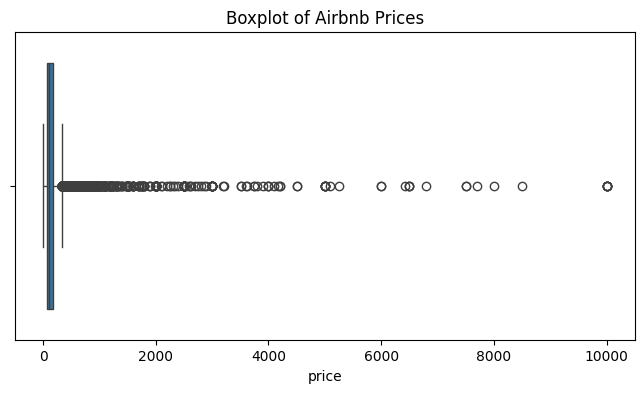

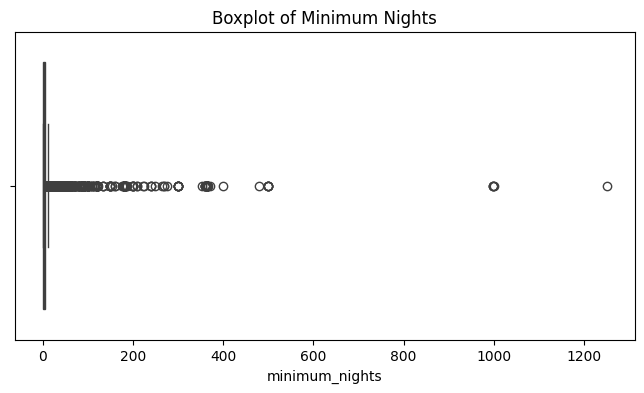

Price 95th Percentile: 355.0
Minimum Nights 95th Percentile: 30.0
Shape After Outlier Treatment: (45748, 10)


In [5]:
# Visualize price outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['price'])
plt.title("Boxplot of Airbnb Prices")
plt.show()

# Visualize minimum nights
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['minimum_nights'])
plt.title("Boxplot of Minimum Nights")
plt.show()

# Remove zero or negative prices
df = df[df['price'] > 0]

# Apply the 95th percentile rule
price_limit = df['price'].quantile(0.95)
nights_limit = df['minimum_nights'].quantile(0.95)

df = df[
    (df['price'] <= price_limit) &
    (df['minimum_nights'] <= nights_limit)
]

# Also exclude extremely long stays
df = df[df['minimum_nights'] < 365]

print("Price 95th Percentile:", price_limit)
print("Minimum Nights 95th Percentile:", nights_limit)
print("Shape After Outlier Treatment:", df.shape)

In [6]:
# Remove the target column from the features
X = df.drop(columns=['price'])
y = df['price']

# One-hot encode categorical variables
X = pd.get_dummies(
    X,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features Shape: (45748, 13)
Target Shape: (45748,)


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,10,9,0.10,1,0,0,1,0,0,0,0


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (36598, 13)
Testing Features: (9150, 13)
Training Target: (36598,)
Testing Target: (9150,)


In [8]:
# Initialize model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict Airbnb prices
y_pred = model.predict(X_test)

print("Model Training Completed!")
print("First 10 Predictions:")
print(y_pred[:10])

Model Training Completed!
First 10 Predictions:
[107.11443193 145.83319005 184.7742995  166.00701944 140.96217236
 157.89799212 145.20004001  72.32528343 142.10058942  90.99570074]


In [9]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("------------------------")
print(f"R-Squared (R²): {r2:.4f}")
print(f"MAE: ${mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: ${rmse:.2f}")

Model Evaluation Results
------------------------
R-Squared (R²): 0.4868
MAE: $38.32
MSE: 2760.62
RMSE: $52.54


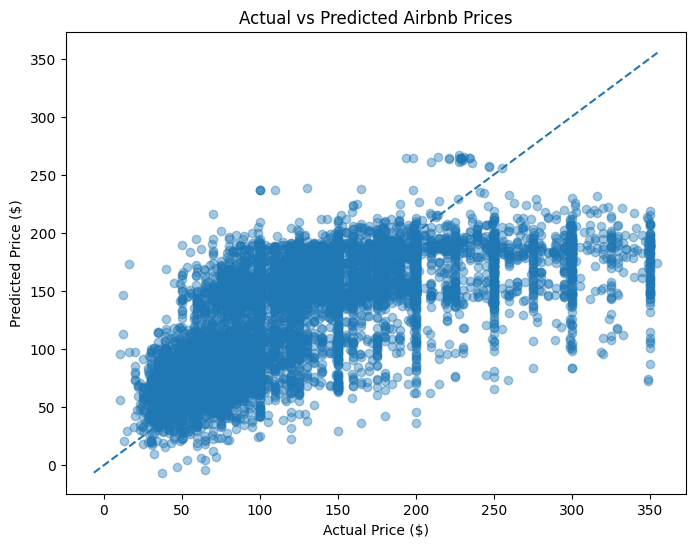

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

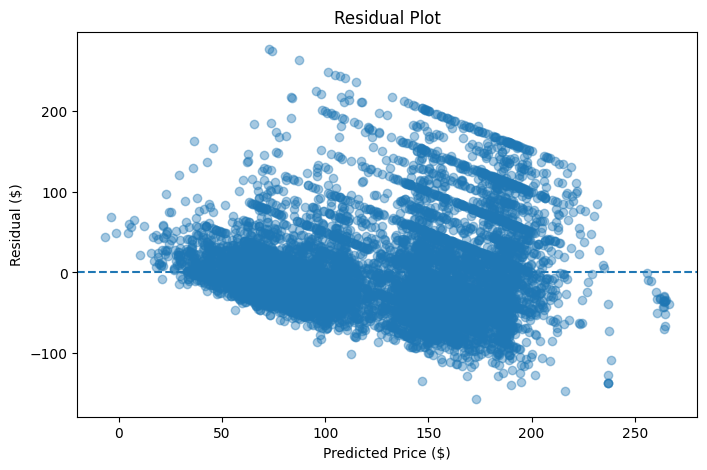

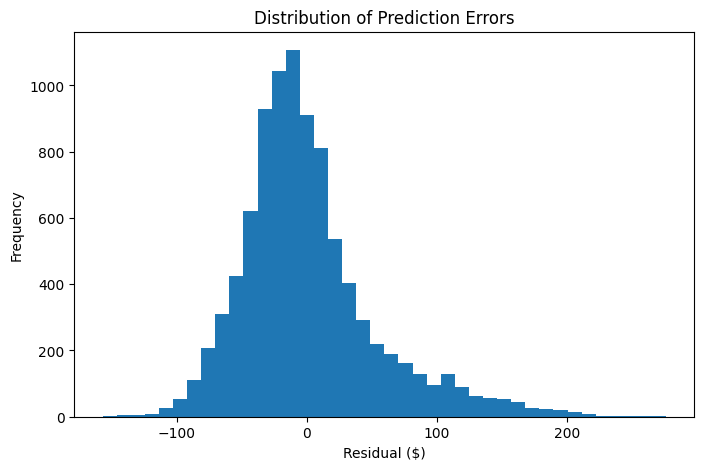

In [11]:
residuals = y_test - y_pred

# Residual plot
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot")
plt.show()

# Error distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40)
plt.xlabel("Residual ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.show()

In [12]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

results['Absolute Error'] = abs(
    results['Actual Price'] - results['Predicted Price']
)

results['Price Group'] = pd.qcut(
    results['Actual Price'],
    q=4,
    labels=[
        'Cheap',
        'Moderate',
        'Expensive',
        'Most Expensive'
    ],
    duplicates='drop'
)

group_errors = results.groupby(
    'Price Group',
    observed=True
)['Absolute Error'].mean()

print("Average Absolute Error by Price Group:")
display(group_errors)

print("\nBest-performing group:")
print(group_errors.idxmin())

Average Absolute Error by Price Group:


,Absolute Error
Price Group,
Cheap,26.211232
Moderate,31.687319
Expensive,31.324502
Most Expensive,64.112438



Best-performing group:
Cheap
